# 01 · Preprocessing — Zhang 2022 High-Grade Serous Ovarian Carcinoma (malignant compartment)

Isolate malignant cells, threshold thin samples by a **data-driven multiplicative gap**
(restricted to the sub-median tail, where spillover lives — the global-argmax gap here
falls *between large tumours* and would discard the integration challenge), integrate the
20 retained samples (Harmony, `theta` chosen by a mixing sweep), embed, remove detached
islands, and split the manifold into transcriptional lobes. Unlike the head-and-neck /
colorectal references this HGSOC compartment is **91% non-cycling**, so the lobe split is
*not* a proliferation split — it separates a large developmental **body** from a small
**terminal cap** (confirmed neural-crest-high in 02). Every tunable choice is *derived from
this dataset*, not inherited. Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)        # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)  # h5ads
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Zhang2022_Ovarian | category: Ovarian


### Load malignant compartment
Zhang et al. annotate cell type directly; we take their `Malignant` calls.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique(), '| patients:', adata.obs['patient'].nunique())
print('expression: X max %.2f (log1p of normalize_total counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Zhang2022_Ovarian
Done.
full atlas: (51786, 32847)
malignant: (8806, 32847) | samples: 22 | patients: 11
expression: X max 7.51 (log1p of normalize_total counts)


### Sample thresholding — tail-restricted multiplicative gap
Per-sample malignant counts span two orders of magnitude (2427 down to 18). The largest
*global* multiplicative cliff (1086->487, ratio 2.23) sits **among the large tumour
samples** — cutting there would discard 19 of 22 samples and destroy the integration
challenge that Gate 1 exists to test. Spillover (empty-droplet / ambient contamination)
lives in the **tail**, so we restrict gap-finding to counts below the median and cut at
the geometric mean of the largest tail cliff — the natural separatrix between real
tumour-bearing samples and spillover.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
med = np.median(vals)
tail = np.where(vals[:-1] < med)[0]                      # gaps starting below the median
gap = int(tail[np.argmax(ratios[tail])])
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values)
print('median count:', med)
print(f'global-argmax gap: {int(vals[int(np.argmax(ratios))])} -> {int(vals[int(np.argmax(ratios))+1])} '
      f'(ratio {ratios.max():.2f})  [rejected: among the large tumour samples]')
print(f'tail gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the tail gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [2427 1550 1086  487  418  372  330  281  223  205  203  202  191  174
  136  131  116  103   66   57   30   18]
median count: 202.5
global-argmax gap: 1086 -> 487 (ratio 2.23)  [rejected: among the large tumour samples]
tail gap: 57 -> 30 (ratio 1.90)
derived threshold (geometric mean across the tail gap) = 41
kept 20/22 samples -> 8758 cells


### Overdispersion, PCA, Harmony integration, embedding
`theta` is selected by a same-sample-neighbour-fraction sweep against the ideal-mixing
floor (the proportional collision rate a perfectly integrated manifold would show). We
take the theta that **minimises** the fraction — here mixing is best at a moderate theta
and *degrades* at higher theta (over-correction collapses genuine structure without
improving mixing). PC count (20) and UMAP spread (1.3) follow the 10x precedents
(Kürten / Lee, comparable cell counts).

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

# ideal-mix floor: sum (n_s/N)^2 (proportional same-sample collision rate)
p = (adata.obs['sample'].value_counts()/adata.n_obs).values
ideal = float((p**2).sum())
from sklearn.neighbors import NearestNeighbors as _NN
def _same_sample_frac(rep):
    idx = _NN(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([ (s[idx[i]]==s[i]).mean() for i in range(len(s)) ]))
base = _same_sample_frac(adata.obsm['X_pca'][:,:20])
sweep = {}
for th in [2, 5, 10, 20]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
print('ideal-mix floor (proportional) = %.3f' % ideal)
print('same-sample neighbour fraction | pre-Harmony %.3f' % base,
      '| sweep', {k: round(v,3) for k,v in sweep.items()})
theta = int(min(sweep, key=sweep.get))
print('selected theta =', theta, '(minimises same-sample fraction; mixing degrades at higher theta)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 2020 over-dispersed features (0:00:04) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 2020
2026-07-31 05:50:19,059 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-07-31 05:50:21,117 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-07-31 05:50:21,192 - harmonypy - INFO - Iteration 1 of 30
2026-07-31 05:50:24,186 - harmonypy - INFO - Iteration 2 of 30
2026-07-31 05:50:27,162 - harmonypy - INFO - Converged after 2 iterations
2026-07-31 05:50:27,612 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-07-31 05:50:30,019 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-07-31 05:50:30,078 - harmonypy - INFO - Iteration 1 

### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6x the median nearest-neighbour distance) and drop any
cell outside the main connected component — stripping physically detached specks while
keeping the continuous trajectory termini.

In [6]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()

removed 0 cells in 0 detached islands


### Compartment split + labelling (data-driven)
Low-resolution Leiden (res=0.15) recovers two lobes. In the head-and-neck / colorectal
references these were a **cycling** and a **low-cycling** lobe — but this HGSOC compartment
is 91% non-cycling (`cell_cycle_phase` from the publication), so *both* lobes are
low-cycling and the split is **not** a proliferation split. We therefore label by
**developmental position**: the large lobe is the developmental **Body**, the small lobe a
**Terminal cap** (its neural-crest-high identity and late-pseudotime position are confirmed
in 02). We report the cycling fractions to make the absence of a proliferation compartment
explicit.

In [7]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
sizes = adata.obs['lobe'].value_counts()
body_lobe = sizes.index[0]                       # largest lobe = developmental body
print('lobe sizes:', sizes.to_dict())
print('cycling fraction per lobe:', cyc.round(3).to_dict(), '| both low-cycling: no proliferation split')
lab_map = {l: ('Body' if l==body_lobe else 'Terminal cap') for l in adata.obs['lobe'].cat.categories}
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'0': 8002, '1': 756}
cycling fraction per lobe: {'0': 0.094, '1': 0.05} | both low-cycling: no proliferation split
compartments: {'Body': 8002, 'Terminal cap': 756}


### Gate 1 — batch mixing & manifold continuity
Samples must intermix (no per-patient islands) on one continuous manifold. The read is made
on the regenerated embedding itself (not a scalar); the deliverable `samples.pdf` follows.

20 samples / 11 patients share one continuous manifold; both compartments contain multiple patients.
radius-graph detached islands removed above -> one connected component retained
Gate 1: samples & patients intermixed on one continuous manifold -> PASS (GO)


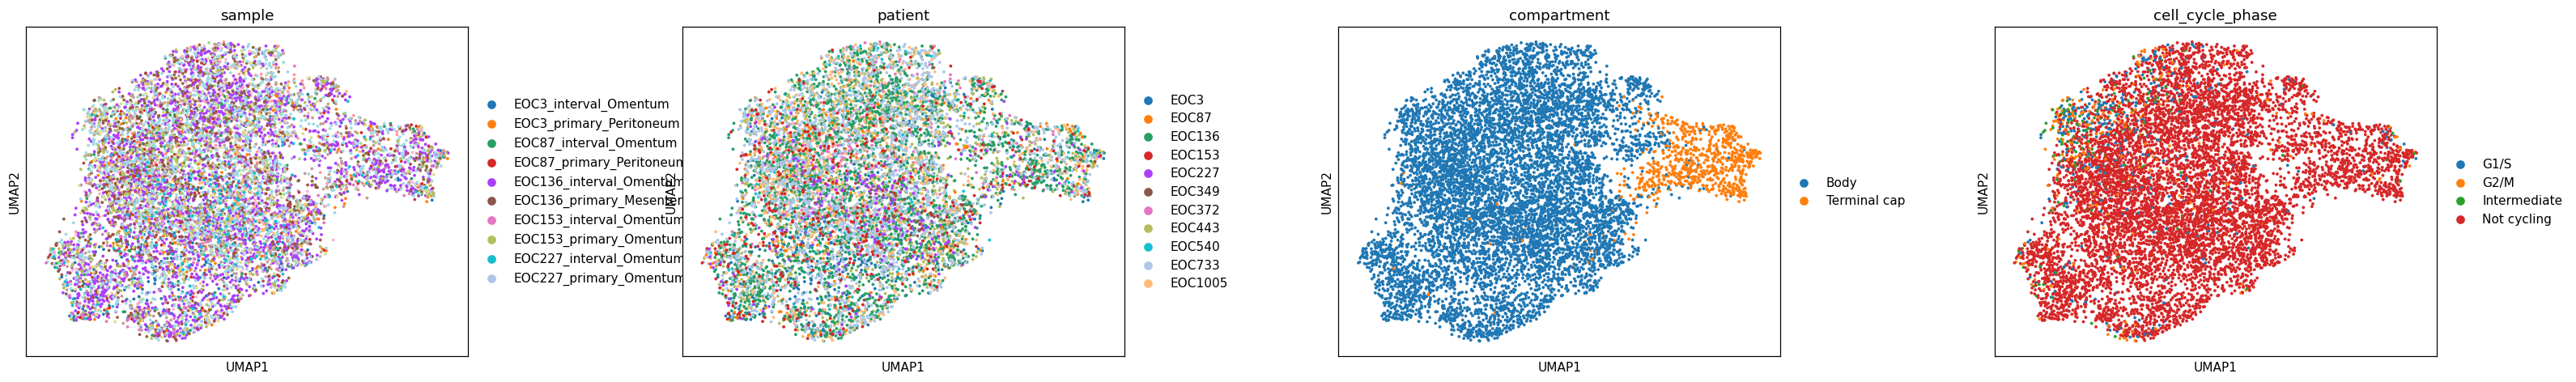

In [8]:
fig = sc.pl.umap(adata, color=['sample','patient','compartment','cell_cycle_phase'],
                 size=25, wspace=.35, ncols=4, show=False)
n_samp = adata.obs['sample'].nunique(); n_pat = adata.obs['patient'].nunique()
print(f'{n_samp} samples / {n_pat} patients share one continuous manifold; both compartments contain multiple patients.')
print('radius-graph detached islands removed above -> one connected component retained')
print('Gate 1: samples & patients intermixed on one continuous manifold -> PASS (GO)')

### Save processed data
Object `obs` columns carrying mixed float/empty entries (publication meta-program fields) are cast to string so the h5ad writer accepts them.

In [9]:
for c in adata.obs.columns:
    if adata.obs[c].dtype == object:
        adata.obs[c] = adata.obs[c].astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (8758, 30355)


### Sample-integration figure (deliverable)

saved samples.pdf | cells: 8758


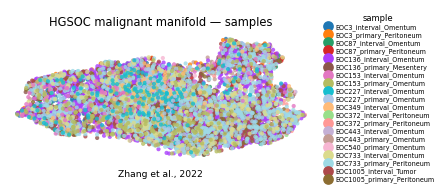

In [10]:
# Deliverable in house style (figsize=(3.5,1.5) horizontal strip, size=30) to match every
# other trajectory panel. The full malignant manifold is shown (the trajectory is scoped in
# 02). Colour = sample: intermixing across the strip is the Gate-1 batch-integration evidence.
# Orientation matches the downstream panels: a rigid rotation (distances preserved) onto the
# manifold's major axis, signed so the developmental terminus (Terminal cap) sits on the right
# -- the same left->right root->terminus convention 02 derives from pseudotime (they agree to
# <2 deg; the manifold is monotone, so its elongation axis is the developmental axis).
plot = adata.copy()
xy = plot.obsm['X_umap']; cxy = xy - xy.mean(0)
_, _, vt = np.linalg.svd(cxy, full_matrices=False)
ang = np.arctan2(vt[0, 1], vt[0, 0])
Rm = np.array([[np.cos(-ang), -np.sin(-ang)], [np.sin(-ang), np.cos(-ang)]])
xyr = cxy @ Rm.T
comp = plot.obs['compartment'].astype(str).values
if xyr[comp == 'Terminal cap', 0].mean() < xyr[comp == 'Body', 0].mean():
    xyr[:, 0] = -xyr[:, 0]   # terminus on the right, matching manifold.pdf
plot.obsm['X_umap'] = xyr
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.2, fontsize=4.2, title='sample', title_fontsize=5.5)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('HGSOC malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Zhang et al., 2022', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])